<a href="https://colab.research.google.com/github/bspineda27/areasinundadasff/blob/main/IslasCalor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Isla de calor urbana en Cúcuta con Big Data espacial
**Taller Big Data Espacial – Especialización en SIG, Universidad Antonio Nariño**
Autora: Brighitte Stefanny Pineda Pardo

**Fuente de datos única:** Landsat Colección 2 Nivel 2 (NASA / USGS), consultada en la nube con Google Earth Engine.

**Uso práctico:** sin descargar ninguna imagen, el script procesa decenas de escenas Landsat de dos periodos (≈2000 y 2025) para:
1. **Mapas de LST** (temperatura superficial) de ≈2000 y 2025.
2. **Mapa de expansión urbana** entre ambos periodos.
3. **Valor de la intensidad de la isla de calor** (ΔT = LST urbana − LST rural, en °C).
4. **Mapa de zonas críticas de calor** en 2025.

> Requisito: una cuenta de Google con Earth Engine habilitado y un proyecto de Google Cloud registrado en Earth Engine.

## 1. Instalación y autenticación

In [1]:
!pip install -q geemap
import ee, geemap
import pandas as pd
import matplotlib.pyplot as plt

PROYECTO = 'accesoparques'   # <-- reemplazar con el ID de tu proyecto de Google Cloud
ee.Authenticate()
ee.Initialize(project=PROYECTO)

## 2. Área de estudio
Rectángulo de unos 17 × 20 km que cubre el casco urbano de Cúcuta, Los Patios, Villa del Rosario y su entorno rural inmediato (Norte de Santander).

In [2]:
aoi = ee.Geometry.Rectangle([-72.60, 7.80, -72.45, 7.98])
print('Área de estudio (km²):', round(aoi.area(10).divide(1e6).getInfo(), 1))

Área de estudio (km²): 330.7


## 3. Preparación de las imágenes Landsat
- Máscara de nubes, sombras y vacíos con la banda `QA_PIXEL`.
- Factores de escala oficiales de la Colección 2 (reflectancia ×0.0000275 − 0.2; temperatura ×0.00341802 + 149 K).
- Temperatura convertida a °C.
- Se usan los meses más secos de Cúcuta (diciembre–marzo y julio–agosto), cuando hay menos nubes.

In [3]:
def mascara_nubes(img):
    qa = img.select('QA_PIXEL')
    despejado = (qa.bitwiseAnd(1).eq(0)            # relleno
                 .And(qa.bitwiseAnd(1 << 1).eq(0))  # nube dilatada
                 .And(qa.bitwiseAnd(1 << 3).eq(0))  # nube
                 .And(qa.bitwiseAnd(1 << 4).eq(0))) # sombra
    return img.updateMask(despejado)

def preparar(img, bandas, termica):
    sr = img.select(bandas, ['rojo', 'nir', 'swir1', 'verde']).multiply(0.0000275).add(-0.2)
    lst = img.select(termica).multiply(0.00341802).add(149.0).subtract(273.15).rename('LST')
    return sr.addBands(lst)

# Landsat 5 y 7 (periodo 2000) y Landsat 8 y 9 (periodo 2025) tienen bandas con nombres distintos
l57 = lambda img: preparar(mascara_nubes(img), ['SR_B3', 'SR_B4', 'SR_B5', 'SR_B2'], 'ST_B6')
l89 = lambda img: preparar(mascara_nubes(img), ['SR_B4', 'SR_B5', 'SR_B6', 'SR_B3'], 'ST_B10')

meses_secos = ee.Filter.Or(ee.Filter.calendarRange(12, 3, 'month'),
                           ee.Filter.calendarRange(7, 8, 'month'))

def cargar(ids, funcion, inicio, fin):
    col = ee.ImageCollection([])
    for i in ids:
        col = col.merge(ee.ImageCollection(i).filterBounds(aoi).filterDate(inicio, fin)
                        .filter(meses_secos).filter(ee.Filter.lt('CLOUD_COVER', 60)).map(funcion))
    return col

col2000 = cargar(['LANDSAT/LT05/C02/T1_L2', 'LANDSAT/LE07/C02/T1_L2'], l57, '1999-01-01', '2002-12-31')
col2025 = cargar(['LANDSAT/LC08/C02/T1_L2', 'LANDSAT/LC09/C02/T1_L2'], l89, '2025-01-01', '2025-12-31')
n2000, n2025 = col2000.size().getInfo(), col2025.size().getInfo()
print('Escenas procesadas  ≈2000:', n2000, ' | 2025:', n2025)

# 2025 es un solo año: si los meses secos dejan muy pocas escenas, se usan todos los meses de 2025
if n2025 < 4:
    meses_secos_2025 = meses_secos
    meses_secos = ee.Filter.calendarRange(1, 12, 'month')
    col2025 = cargar(['LANDSAT/LC08/C02/T1_L2', 'LANDSAT/LC09/C02/T1_L2'], l89, '2025-01-01', '2025-12-31')
    meses_secos = meses_secos_2025
    print('Pocas escenas en meses secos; se usan todos los meses de 2025:', col2025.size().getInfo())

Escenas procesadas  ≈2000: 46  | 2025: 24


## 4. Compuestos e índices espectrales
Se combina cada periodo en una sola imagen (mediana: ≈2000 = 1999–2002; 2025 = escenas de ese año) y se calculan:
- **NDVI** (vegetación) = (NIR − Rojo) / (NIR + Rojo)
- **NDBI** (superficie construida) = (SWIR1 − NIR) / (SWIR1 + NIR)
- **MNDWI** (agua) = (Verde − SWIR1) / (Verde + SWIR1)

In [4]:
def compuesto(col):
    img = col.median().clip(aoi)
    ndvi = img.normalizedDifference(['nir', 'rojo']).rename('NDVI')
    ndbi = img.normalizedDifference(['swir1', 'nir']).rename('NDBI')
    mndwi = img.normalizedDifference(['verde', 'swir1']).rename('MNDWI')
    return img.addBands([ndvi, ndbi, mndwi])

img2000 = compuesto(col2000)
img2025 = compuesto(col2025)

## 5. Mancha urbana, zona rural y RESULTADO 3 – intensidad de la isla de calor
Con los mismos datos Landsat se clasifica cada píxel:
- **Urbano:** NDBI > 0 y NDVI < 0,25 (superficies construidas, poca vegetación).
- **Rural de referencia:** NDVI > 0,40 (vegetación densa).
- Se excluye el agua (MNDWI > 0).

Los umbrales son una aproximación básica; el suelo desnudo, frecuente en el clima seco de Cúcuta, puede confundirse con zona construida.

In [5]:
def zonas(img):
    agua = img.select('MNDWI').gt(0)
    urbano = img.select('NDBI').gt(0).And(img.select('NDVI').lt(0.25)).And(agua.Not())
    rural = img.select('NDVI').gt(0.40).And(agua.Not())
    return urbano, rural

def media(img, banda, mascara):
    return img.select(banda).updateMask(mascara).reduceRegion(
        ee.Reducer.mean(), aoi, scale=30, maxPixels=1e10).get(banda)

def area_km2(mascara):
    return mascara.selfMask().multiply(ee.Image.pixelArea()).reduceRegion(
        ee.Reducer.sum(), aoi, scale=30, maxPixels=1e10).values().get(0)

filas = []
for periodo, img in [('≈2000', img2000), ('2025', img2025)]:
    urbano, rural = zonas(img)
    d = ee.Dictionary({'u': media(img, 'LST', urbano), 'r': media(img, 'LST', rural),
                       'a': area_km2(urbano)}).getInfo()
    filas.append({'Periodo': periodo,
                  'Área urbana (km²)': d['a'] / 1e6,
                  'LST urbana (°C)': d['u'],
                  'LST rural (°C)': d['r'],
                  'Isla de calor ΔT (°C)': d['u'] - d['r']})
tabla = pd.DataFrame(filas).round(1)
crec = (tabla.loc[1, 'Área urbana (km²)'] / tabla.loc[0, 'Área urbana (km²)'] - 1) * 100
print(f'Crecimiento de la mancha urbana: {crec:.0f} %')
print(f"Intensidad de la isla de calor (ΔT): ≈2000 = {tabla.loc[0, 'Isla de calor ΔT (°C)']} °C | 2025 = {tabla.loc[1, 'Isla de calor ΔT (°C)']} °C")
tabla

Crecimiento de la mancha urbana: 42 %
Intensidad de la isla de calor (ΔT): ≈2000 = 5.8 °C | 2025 = 5.4 °C


,Periodo,Área urbana (km²),LST urbana (°C),LST rural (°C),Isla de calor ΔT (°C)
0,≈2000,23.4,38.9,33.1,5.8
1,2025,33.2,43.7,38.4,5.4


## 5. Mancha urbana, zona rural y RESULTADO 3 – intensidad de la isla de calor
Con los mismos datos Landsat se clasifica cada píxel:
- **Urbano:** NDBI > 0 y NDVI < 0,25 (superficies construidas, poca vegetación).
- **Rural de referencia:** NDVI > 0,40 (vegetación densa).
- Se excluye el agua (MNDWI > 0).

Los umbrales son una aproximación básica; el suelo desnudo, frecuente en el clima seco de Cúcuta, puede confundirse con zona construida.

## 6. RESULTADO 1 – Mapas de LST: temperatura ≈2000 vs 2025
Mueva el control deslizante para comparar. Rojo = superficies más calientes.

In [7]:
vis_lst = {'min': 26, 'max': 48, 'palette': ['040274', '0502ce', '30c8e2', '86e26f', 'f5f500', 'ffa600', 'ff0000', 'a71001']}
Map = geemap.Map(center=[7.89, -72.51], zoom=12, basemap='Esri.WorldImagery')
Map.split_map(geemap.ee_tile_layer(img2000.select('LST'), vis_lst, 'LST ≈2000'),
              geemap.ee_tile_layer(img2025.select('LST'), vis_lst, 'LST 2025'))
Map.add_colorbar(vis_lst, label='Temperatura superficial (°C)')
Map

Map(center=[7.89, -72.51], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

## 7. RESULTADO 2 – Mapa de expansión urbana
Gris = urbano en ambos periodos; naranja = nuevo suelo urbano entre ≈2000 y 2025.

In [8]:
u2000, _ = zonas(img2000)
u2025, _ = zonas(img2025)
nuevo = u2025.And(u2000.Not())

Map2 = geemap.Map(center=[7.89, -72.51], zoom=12, basemap='Esri.WorldImagery')
Map2.add_basemap('SATELLITE')
Map2.addLayer(u2000.selfMask(), {'palette': ['808080']}, 'Urbano ≈2000')
Map2.addLayer(nuevo.selfMask(), {'palette': ['ff8c00']}, 'Nuevo urbano 2000–2025')
Map2

Map(center=[7.89, -72.51], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 8. ¿La vegetación enfría la ciudad?
Muestra de 3 000 píxeles de 2025.

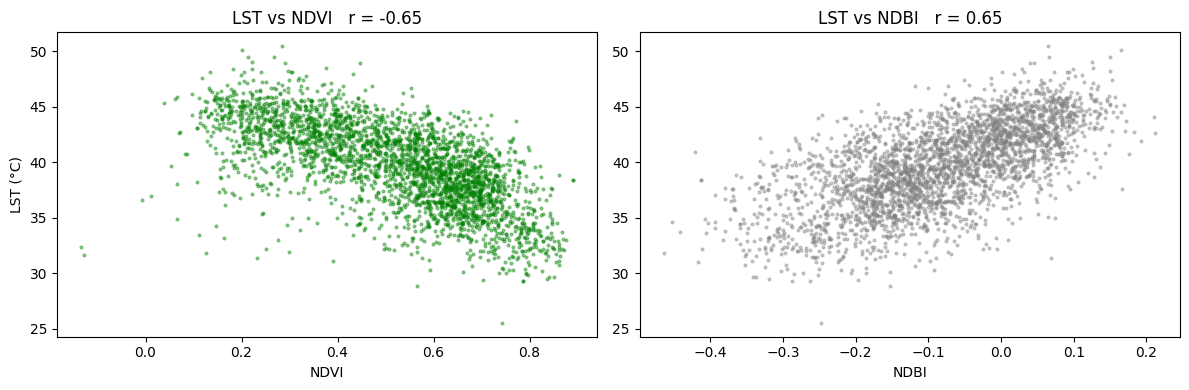

In [9]:
muestra = img2025.select(['LST', 'NDVI', 'NDBI']).sample(region=aoi, scale=30, numPixels=3000, seed=1).getInfo()
m = pd.DataFrame([f['properties'] for f in muestra['features']]).dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(m.NDVI, m.LST, s=4, alpha=.4, color='green')
ax[0].set(xlabel='NDVI', ylabel='LST (°C)', title=f'LST vs NDVI   r = {m.LST.corr(m.NDVI):.2f}')
ax[1].scatter(m.NDBI, m.LST, s=4, alpha=.4, color='gray')
ax[1].set(xlabel='NDBI', title=f'LST vs NDBI   r = {m.LST.corr(m.NDBI):.2f}')
plt.tight_layout(); plt.show()

## 9. RESULTADO 4 – Mapa de zonas críticas de calor (2025)
Dentro de la mancha urbana 2025, se marcan como **críticos** los píxeles cuya temperatura supera la media urbana en más de 1,5 desviaciones estándar. Son los sectores donde priorizar arborización, parques y cubiertas frías.

In [10]:
lst_u = img2025.select('LST').updateMask(u2025)
p = lst_u.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
                       aoi, scale=30, maxPixels=1e10)
z = lst_u.subtract(ee.Number(p.get('LST_mean'))).divide(ee.Number(p.get('LST_stdDev')))
criticas = z.gt(1.5)
print('Área urbana crítica (ha):', round(ee.Number(area_km2(criticas)).divide(1e4).getInfo(), 1))

Map3 = geemap.Map(center=[7.89, -72.51], zoom=13, basemap='Esri.WorldImagery')
Map3.add_basemap('SATELLITE')
Map3.addLayer(z, {'min': -2, 'max': 2, 'palette': ['2c7bb6', 'ffffbf', 'd7191c']}, 'Anomalía de temperatura urbana (z)')
Map3.addLayer(criticas.selfMask(), {'palette': ['8b0000']}, 'Zonas críticas (z > 1,5)')
Map3

Área urbana crítica (ha): 127.2


Map(center=[7.89, -72.51], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 10. Exportar a Google Drive (opcional)
GeoTIFF en EPSG:9377 (Origen Nacional) para cruzarlos en ArcGIS o QGIS con barrios y comunas.

In [11]:
for nombre, img in [('LST_2000', img2000.select('LST')), ('LST_2025', img2025.select('LST')),
                    ('zonas_criticas_2025', criticas.selfMask())]:
    ee.batch.Export.image.toDrive(image=img.toFloat(), description=nombre, folder='ICU_Cucuta',
                                  region=aoi, scale=30, crs='EPSG:9377', maxPixels=1e10).start()
print('Exportaciones enviadas: revise la carpeta ICU_Cucuta en Google Drive.')

Exportaciones enviadas: revise la carpeta ICU_Cucuta en Google Drive.


## Limitaciones
- La LST es la temperatura **de la superficie**, no del aire.
- La clasificación urbana por umbrales es básica: el suelo desnudo puede aparecer como urbano.
- Landsat 7 después de 2003 tiene franjas sin datos; la mediana de varios años las compensa en parte.
- 2025 se calcula con un solo año, así que tiene menos escenas que el periodo ≈2000 y es más sensible a las condiciones de ese año.
- El rectángulo de estudio toca el límite con Venezuela en el costado oriental.